# 01 · Exploratory Data Analysis (EDA)
**Project:** Tweet Emotion Detection · **Dataset:** TweetEval `emotion` (HuggingFace `cardiffnlp/tweet_eval`)

**Scope.** This notebook only *explores* the raw dataset as a whole. It does **not** clean, preprocess or vectorise the text;
those are separate steps (`02_preprocessing`, `03_representation`). Word counts here use a plain regex split, only to measure the raw text.

### EDA questions

| # | Question |
|---|---|
| Q1 | What does the dataset look like (size, columns, labels, examples)? |
| Q2 | How clean is the raw text (missing values, duplicates, noise)? |
| Q3 | How are the emotions distributed? Is the dataset balanced? |
| Q4 | How long are the tweets, and does length differ by emotion? |
| Q5 | Which Twitter-specific elements (mentions, hashtags, emojis, punctuation, caps) appear, and how do they vary by emotion? |
| Q6 | Which hashtags and emojis are most common for each emotion? |
| Q7 | How large is the vocabulary, and how are word frequencies distributed? |
| Q8 | Which words are most characteristic of each emotion? |
| Q9 | How common is negation in each emotion? |

# Setup

In [21]:
import os, re, warnings
from collections import Counter
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", message="This pattern is interpreted")
pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")

DATA_DIR, FIG_DIR = "../data", "../results/figures/eda"
os.makedirs(FIG_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

LABELS = ["anger", "joy", "optimism", "sadness"]
PALETTE = {"anger": "#d62728", "joy": "#ffbf00", "optimism": "#2ca02c", "sadness": "#1f77b4"}

## Load the raw dataset
HuggingFace ships the data in three parts; for EDA we combine them into **one raw dataset**.
A local copy is kept in `data/` (required for submission) and downloaded again if missing.

In [22]:
PARTS = ["train", "validation", "test"]
if not all(os.path.exists(f"{DATA_DIR}/{p}.csv") for p in PARTS):
    from datasets import load_dataset
    ds = load_dataset("cardiffnlp/tweet_eval", "emotion")
    os.makedirs(DATA_DIR, exist_ok=True)
    for p in PARTS:
        ds[p].to_pandas().to_csv(f"{DATA_DIR}/{p}.csv", index=False)

df = pd.concat([pd.read_csv(f"{DATA_DIR}/{p}.csv") for p in PARTS], ignore_index=True)
# Plain Python strings: avoids pyarrow string/bool dtypes (RE2 regex limits, plotting errors)
df["text"] = df["text"].astype(object)
df["emotion"] = df["label"].map(dict(enumerate(LABELS)))

## Q1. What does the dataset look like?

In [23]:
print("Rows:", len(df), "| Columns:", list(df.columns[:2]))
print("Label mapping:", dict(enumerate(LABELS)))
df.info()

Rows: 5052 | Columns: ['text', 'label']
Label mapping: {0: 'anger', 1: 'joy', 2: 'optimism', 3: 'sadness'}
<class 'pandas.DataFrame'>
RangeIndex: 5052 entries, 0 to 5051
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   text     5052 non-null   object
 1   label    5052 non-null   int64 
 2   emotion  5052 non-null   str   
dtypes: int64(1), object(1), str(1)
memory usage: 145.4+ KB


In [24]:
df[['text', 'label', 'emotion']].sample(8, random_state=1)

,text,label,emotion
3472,@user Hahaha got the same forward !! I want to find the source and teach 🤣,1,joy
2860,"@user SPARKLES, proud little huff. Still posing mind you.",2,optimism
1796,@user beware the fury of a weak king,2,optimism
4021,@user Unbelievable #arrogance to think you know better than #StephenHawking .,0,anger
1675,On the last episode of #MakingAMurderer poor Brendan glad they #appeal it #crime #documentary #reallife,1,joy
1528,the teams that face Barca and Bayern after a defeat are the ones who face the wrath,0,anger
4623,I hate getting woken up out my sleep 😡,0,anger
834,Why doesn't anybody I know watch penny dreadful? ☹️️,3,sadness


## Q2. How clean is the raw text?

In [25]:
checks = {
    "missing text": df.text.isna().sum(),
    "missing label": df.label.isna().sum(),
    "empty / whitespace-only text": (df.text.str.strip() == "").sum(),
    "duplicate tweets (extra copies)": df.duplicated("text").sum(),
    "same text with different labels": (df.groupby("text").emotion.nunique() > 1).sum(),
    "literal '\\n' (backslash + n)": df.text.str.contains("\\n", regex=False).sum(),
    "HTML entities (&amp; &lt; ...)": df.text.str.contains(r"&\w+;").sum(),
    "curly apostrophe ’": df.text.str.contains("’", regex=False).sum(),
    "URLs": df.text.str.contains(r"https?://|www\.").sum(),
}
pd.Series(checks).to_frame("number of tweets")

,number of tweets
missing text,0
missing label,0
empty / whitespace-only text,0
duplicate tweets (extra copies),25
same text with different labels,0
literal '\n' (backslash + n),279
HTML entities (&amp; &lt; ...),240
curly apostrophe ’,43
URLs,0


In [26]:
dups = df[df.duplicated("text", keep=False)]
dups.groupby(["text", "emotion"]).size().rename("copies").sort_values(ascending=False).reset_index()

,text,emotion,copies
0,Watch this amazing live.ly broadcast by @user #musically,joy,15
1,Watch this amazing live.ly broadcast by @user #lively #musically,joy,12


In [27]:
# Examples of noisy tweets
for pat in ["\\n", "&amp;"]:
    print(f"--- contains {pat!r} ---")
    for t in df[df.text.str.contains(pat, regex=False)].text.head(3):
        print(" •", t)

--- contains '\\n' ---
 • @user @user @user Tamra would F her up if she swung on Tamra\nKelly is a piece of 💩 #needstobeadmitted #bully
 • her; i want a playful relationship\nme; *kicks her off the couch*
 • “ My courage always rises at every attempt to intimidate me.”\n-Elizabeth Bennett (Pride and Prejudice)\n#Quotes #Courage #FaceYourFears
--- contains '&amp;' ---
 • #NewYork: Several #Baloch &amp; Indian activists hold demonstrations outside @user headquarters demanding Pak to stop exporting #terror into India
 • Your glee filled Normy dry humping of the most recent high profile celebrity break up is pathetic &amp; all that is wrong with the world today.
 • #FF \n\n@The_Family_X \n\n#soul #blues &amp; #rock #band\n\n#music from the #heart\n\nWith soul &amp; #passion \n\nXx 🎶 xX


## Q3. How are the emotions distributed?

,tweets,%
emotion,,
anger,2118,41.9
joy,1163,23.0
optimism,445,8.8
sadness,1326,26.2


Imbalance ratio (largest / smallest): 4.76


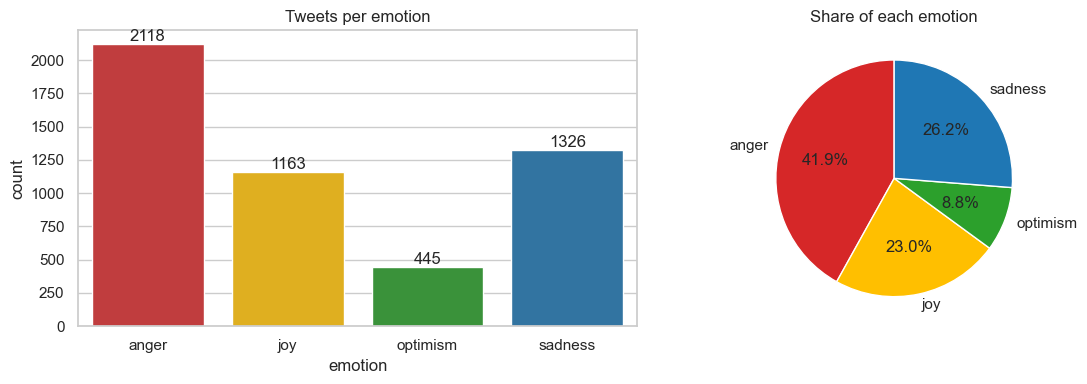

In [28]:
dist = df.emotion.value_counts().reindex(LABELS).to_frame("tweets")
dist["%"] = (dist.tweets / len(df) * 100).round(1)
display(dist)
print(f"Imbalance ratio (largest / smallest): {dist.tweets.max() / dist.tweets.min():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="emotion", hue="emotion", order=LABELS, palette=PALETTE, legend=False, ax=ax[0])
for c in ax[0].containers:
    ax[0].bar_label(c)
ax[0].set_title("Tweets per emotion")
ax[1].pie(dist.tweets, labels=LABELS, autopct="%1.1f%%", colors=[PALETTE[l] for l in LABELS], startangle=90)
ax[1].set_title("Share of each emotion")
plt.tight_layout(); savefig("class_distribution"); plt.show()

## Q4. How long are the tweets?
Two different length measures:
- **`n_chars`**: number of **characters**, counted with `str.len()` (letters, spaces, punctuation and emojis all count).
- **`n_words`**: number of **words**, counted with `str.split()` (pieces of text separated by whitespace; `@user`, `#hashtag` and `!!` each count as one).

In [41]:
df["n_chars"] = df.text.str.len()
df["n_words"] = df.text.str.split().str.len()

# display(df[["n_chars", "n_words"]].describe().round(1).T)
# display(df.groupby("emotion")[["n_chars", "n_words"]].median().loc[LABELS].rename(columns=lambda c: "median " + c))

print("Total characters:", df["n_chars"].sum())
print("Total words:", df["n_words"].sum())

Total characters: 458076
Total words: 81100


## Q5. Which Twitter-specific elements appear?

emotion,all tweets,anger,joy,optimism,sadness
% of tweets containing,,,,,
mention (@user),44.3,50.0,49.7,30.6,35.1
hashtag,45.3,43.1,45.9,47.0,47.7
emoji,16.0,11.3,26.7,5.2,17.8
exclamation !,14.1,15.0,20.6,9.2,8.6
question ?,11.0,14.0,7.7,7.2,10.3
ALL-CAPS word,9.9,11.9,10.9,7.9,6.4
elongated word (sooo),1.7,1.8,2.3,0.0,1.6
number,10.2,10.5,10.3,10.3,9.7


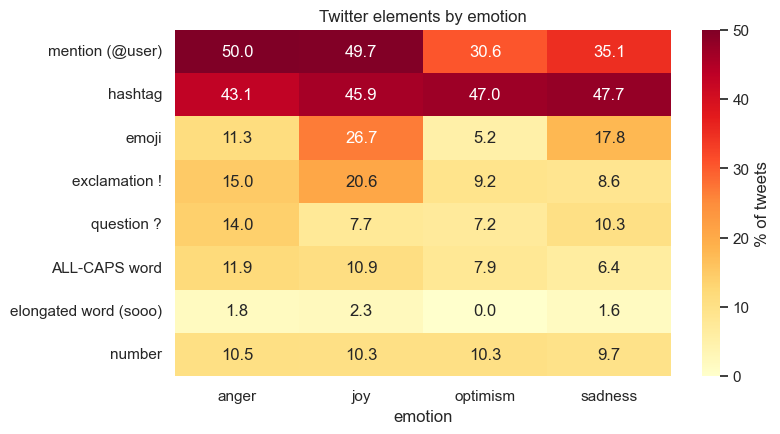

In [42]:
# RE2-safe (no back-references), works with pyarrow string dtype
ELONGATED_RE = "|".join(f"{c}{{3,}}" for c in "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ")
EMOJI_RE = "[\U0001F300-\U0001FAFF\U00002600-\U000027BF\U0001F1E6-\U0001F1FF]"
ELEMENTS = {
    "mention (@user)": r"@\w+",
    "hashtag": r"#\w+",
    "emoji": EMOJI_RE,
    "exclamation !": r"!",
    "question ?": r"\?",
    "ALL-CAPS word": r"\b[A-Z]{3,}\b",
    "elongated word (sooo)": ELONGATED_RE,
    "number": r"\b\d+\b",
}
for name, p in ELEMENTS.items():
    df[name] = df.text.str.contains(p)

share = (df.groupby("emotion")[list(ELEMENTS)].mean().T * 100).round(1)[LABELS]
share.insert(0, "all tweets", (df[list(ELEMENTS)].mean() * 100).round(1))
display(share.rename_axis("% of tweets containing"))

plt.figure(figsize=(8, 4.5))
sns.heatmap(share[LABELS], annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "% of tweets"})
plt.title("Twitter elements by emotion")
savefig("twitter_elements"); plt.show()

## Q6. Most common hashtags and emojis per emotion

In [32]:
def top_items(pattern, n=10, lower=True):
    out = {}
    for e in LABELS:
        items = df[df.emotion == e].text.str.findall(pattern).explode().dropna()
        if lower:
            items = items.str.lower()
        out[e] = items.value_counts().head(n).index.to_series(index=range(min(n, items.nunique())))
    return pd.DataFrame(out)

print("Unique hashtags:", df.text.str.findall(r"#\w+").explode().dropna().str.lower().nunique())
top_items(r"#\w+")

Unique hashtags: 2725


,anger,joy,optimism,sadness
0,#angry,#hilarious,#fear,#sad
1,#fuming,#musically,#optimism,#depression
2,#awful,#blues,#quote,#sadness
3,#rage,#happy,#worry,#anxiety
4,#terrible,#lively,#terrorism,#depressing
5,#horrible,#funny,#afraid,#lost
6,#shocking,#smile,#faith,#nightmare
7,#anger,#horror,#life,#depressed
8,#bully,#lol,#success,#panic
9,#terrorism,#amazing,#relentless,#restless


In [33]:
top_items(EMOJI_RE, n=8, lower=False)

,anger,joy,optimism,sadness
0,😂,😂,✨,😭
1,😡,😍,❤,😢
2,😠,❤,🙈,😂
3,😤,😘,🍃,😩
4,🙄,😊,🙏,☹
5,🏻,💖,🏾,💔
6,🙈,😭,😂,🙄
7,🔥,🤣,✌,😰


## Q7. How large is the vocabulary?
Words are counted with a plain regex (`[a-z']+` on lowercased text). This is a measurement only, not the preprocessing step.

In [34]:
df["words"] = df.text.str.lower().str.findall(r"[a-z']+")
vocab = Counter(w for ws in df.words for w in ws)
hapax = sum(c == 1 for c in vocab.values())

print(f"Total words: {sum(vocab.values()):,}")
print(f"Vocabulary size (unique words): {len(vocab):,}")
print(f"Words that occur only once: {hapax:,} ({hapax / len(vocab):.1%} of the vocabulary)")
top20 = sum(c for _, c in vocab.most_common(20)) / sum(vocab.values())
print(f"The 20 most frequent words cover {top20:.1%} of all word occurrences")

Total words: 80,491
Vocabulary size (unique words): 11,577
Words that occur only once: 6,731 (58.1% of the vocabulary)
The 20 most frequent words cover 26.9% of all word occurrences


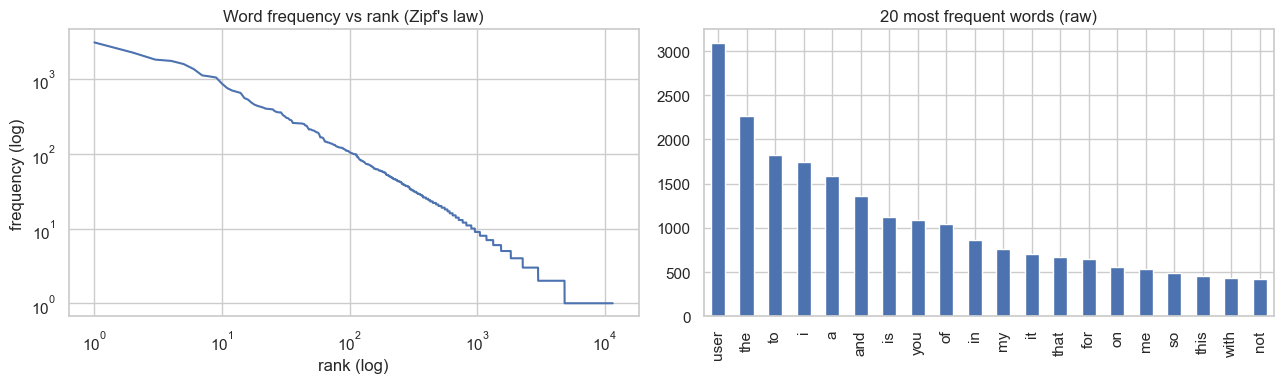

In [35]:
freqs = np.array(sorted(vocab.values(), reverse=True))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].loglog(np.arange(1, len(freqs) + 1), freqs)
ax[0].set(title="Word frequency vs rank (Zipf's law)", xlabel="rank (log)", ylabel="frequency (log)")
pd.Series(dict(vocab.most_common(20))).plot(kind="bar", ax=ax[1])
ax[1].set_title("20 most frequent words (raw)")
plt.tight_layout(); savefig("vocabulary"); plt.show()

## Q8. Which words are most characteristic of each emotion?
Raw frequency is dominated by words like *the*, *to*, *i* in every emotion, so instead we rank words by the
**weighted log-odds ratio** (Monroe et al., 2008): how much more often a word appears in one emotion than in the others.
Common words get a score near 0 automatically, so no stop-word list is needed.

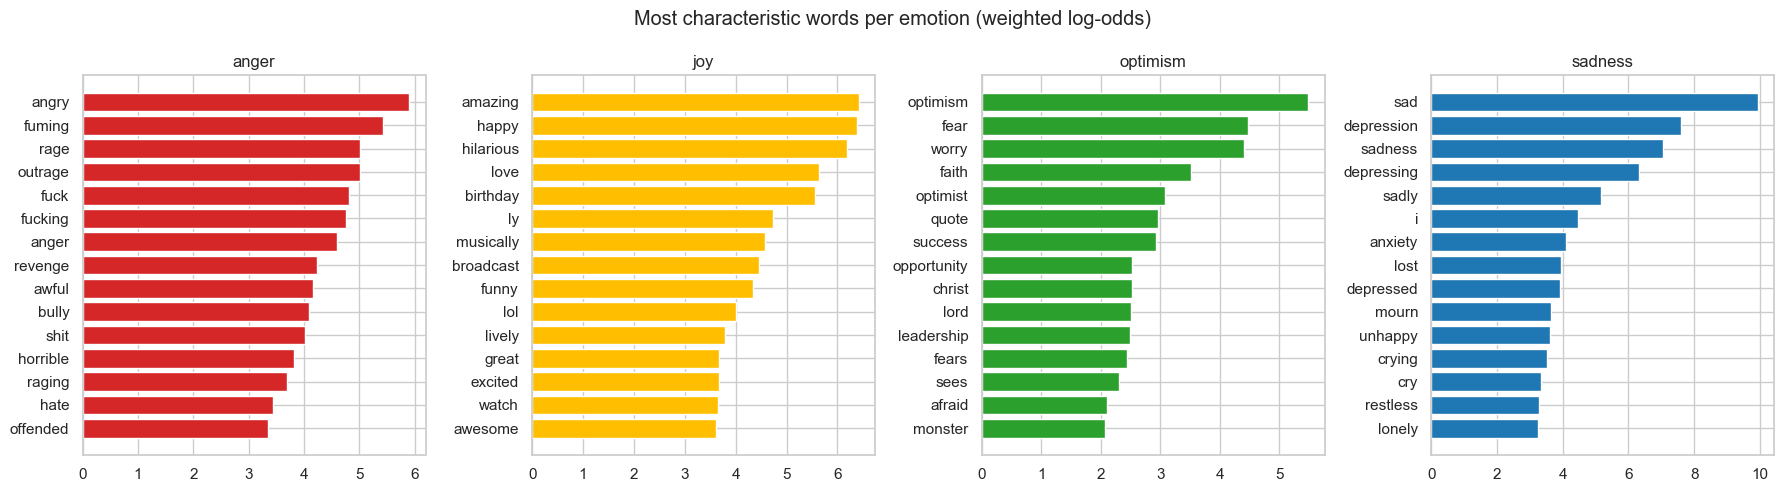

In [36]:
def log_odds(a, b, prior):
    na, nb, a0 = sum(a.values()), sum(b.values()), sum(prior.values())
    scores = {}
    for w, aw in prior.items():
        ya, yb = a.get(w, 0), b.get(w, 0)
        delta = np.log((ya + aw) / (na + a0 - ya - aw)) - np.log((yb + aw) / (nb + a0 - yb - aw))
        scores[w] = delta / np.sqrt(1 / (ya + aw) + 1 / (yb + aw))
    return pd.Series(scores)

counts = {e: Counter(w for ws in df[df.emotion == e].words for w in ws) for e in LABELS}
top = {}
for e in LABELS:
    rest = sum((counts[o] for o in LABELS if o != e), Counter())
    top[e] = log_odds(counts[e], rest, vocab).nlargest(15)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, e in zip(axes, LABELS):
    s = top[e][::-1]
    ax.barh(s.index, s.values, color=PALETTE[e]); ax.set_title(e)
plt.suptitle("Most characteristic words per emotion (weighted log-odds)")
plt.tight_layout(); savefig("characteristic_words"); plt.show()

## Q9. How common is negation?

Tweets with negation (all): 26.2%


,% with negation
emotion,
anger,29.5
joy,13.6
optimism,34.4
sadness,29.2


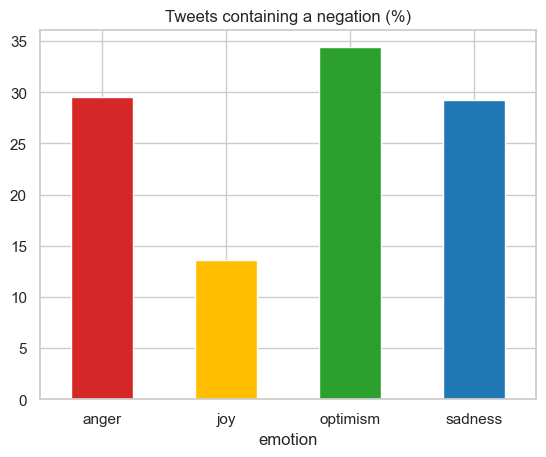

In [37]:
NEG_RE = r"\b(?:not|no|never|nothing|nobody|none|nor|cannot|neither|nowhere)\b|n't\b"
df["has_negation"] = df.text.str.lower().str.replace("’", "'").str.contains(NEG_RE)

neg = (df.groupby("emotion").has_negation.mean() * 100).round(1).loc[LABELS]
print(f"Tweets with negation (all): {df.has_negation.mean():.1%}")
display(neg.to_frame("% with negation"))
neg.plot(kind="bar", color=[PALETTE[l] for l in LABELS], rot=0, title="Tweets containing a negation (%)")
savefig("negation"); plt.show()

In [38]:
for e in LABELS:
    print(f"--- {e} ---")
    for t in df[(df.emotion == e) & df.has_negation].text.sample(2, random_state=0):
        print(" •", t)

--- anger ---
 • @user Yeah, but bad part is the #terrorism #terror Muslims won't be the ones leaving #ObamaLegacy #nationalsecurity #disaster #Obama
 • @user what can we do 2 get @user 2 reveal his taxes? That is the immediate danger. But u will not answer me.
--- joy ---
 • These girls who are playful and childlike seem to have such lovely relationships. Can't imagine them having serious convos but it's cute  😍😍
 • @user @user lol no it's sparkling wine
--- optimism ---
 • @user I know if I wasn't an optimist I would despair.
 • @user DO THE THING enrage all the people who cannot Do The Thing
--- sadness ---
 • @user #mhchat Childhood experiences inform adult relationships. We have associative memories Not a question of ability to process #sadness
 • @user I worry about typos in any email to Simon, draft attached or not...


## Summary of EDA findings

| # | Question | Finding |
|---|---|---|
| Q1 | Dataset overview | 5,052 tweets · `text` + `label` · 4 emotions · `@user` anonymised |
| Q2 | Data quality | Complete (no missing, no label conflicts); noise: 25 spam duplicates, 279 literal `\n`, 240 HTML entities, 43 curly `’`, no URLs |
| Q3 | Class distribution | Imbalanced: anger 41.9% · sadness 26.2% · joy 23.0% · optimism 8.8% (ratio 4.8) |
| Q4 | Tweet length | Short (mean 16 words); similar across emotions |
| Q5 | Twitter elements | Hashtags 45%, mentions 44%, emojis 16% (most in joy); `!` → joy, `?` → anger |
| Q6 | Hashtags & emojis | Often name the emotion directly (`#angry`, `#sad`, 😡, 😭) |
| Q7 | Vocabulary | 11.6k unique words, 58% appear once; follows Zipf's law |
| Q8 | Characteristic words | Clear keywords per emotion; optimism overlaps with fear/worry words |
| Q9 | Negation | 26% of tweets; most in optimism/anger/sadness, least in joy |

### Points to consider in the next steps
- **Preprocessing:** the noise from Q2 (duplicates, `\n`, `&amp;`, `’`), `@user`, hashtags and emojis that carry emotion (Q5–Q6), and negation words (Q9).
- **Modelling & evaluation:** class imbalance (Q3) and the overlap between optimism and the negative emotions (Q8).